# 03 – Baseline: TF-IDF + Logistic Regression
Non-neural reference model; settings chosen on validation, test used once.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

from src.data import load_split, LABELS, SEED, RESULTS_DIR, ROOT as PROJECT_ROOT
from src.plotting import set_style, save, SERIES, TEXT, TEXT_SECONDARY
from src.evaluate import record_metrics, per_class_report, save_predictions, plot_confusion_matrix

set_style()
train, val, test = load_split("train"), load_split("val"), load_split("test")
print({n: len(d) for n, d in [("train", train), ("val", val), ("test", test)]})

{'train': 32884, 'val': 7047, 'test': 7047}


## 1. Tune on validation
Words vs. words + pairs, class weighting on/off, regularisation strength C.

In [2]:
def build(ngram, balanced, C):
    return make_pipeline(
        TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True),
        LogisticRegression(C=C, max_iter=3000, class_weight="balanced" if balanced else None, random_state=SEED),
    )

rows = []
for ngram in [(1, 1), (1, 2)]:
    for balanced in [False, True]:
        for C in [0.5, 1, 2, 5, 10, 20]:
            t0 = time.time()
            m = build(ngram, balanced, C).fit(train.text, train.label)
            pred = m.predict(val.text)
            rows.append({"features": "words" if ngram == (1, 1) else "words + pairs",
                         "class_weight": "balanced" if balanced else "none", "C": C,
                         "val_macro_f1": f1_score(val.label, pred, average="macro"),
                         "val_accuracy": (pred == val.label).mean(),
                         "fit_seconds": round(time.time() - t0, 1)})
grid = pd.DataFrame(rows)
grid.to_csv(RESULTS_DIR / "baseline_tuning.csv", index=False)
grid.sort_values("val_macro_f1", ascending=False).head(8).round(4)

,features,class_weight,C,val_macro_f1,val_accuracy,fit_seconds
21,words + pairs,balanced,5.0,0.8697,0.8673,12.5
22,words + pairs,balanced,10.0,0.8669,0.8643,14.9
23,words + pairs,balanced,20.0,0.8657,0.8626,14.7
20,words + pairs,balanced,2.0,0.8637,0.8616,9.2
17,words + pairs,none,20.0,0.8627,0.8595,13.8
16,words + pairs,none,10.0,0.8621,0.8595,14.6
15,words + pairs,none,5.0,0.8616,0.8604,13.6
3,words,none,5.0,0.8613,0.8543,2.4


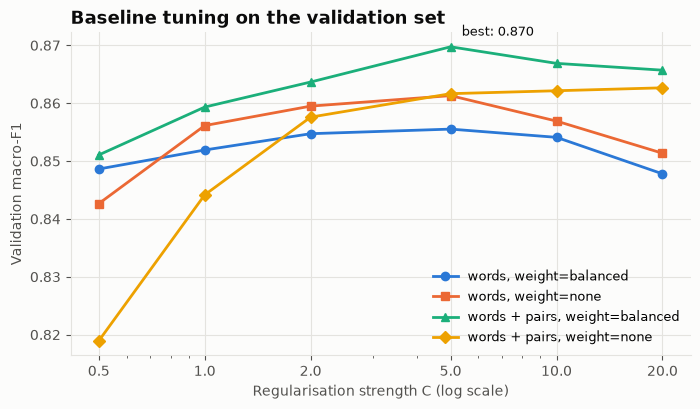

In [3]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
markers = ["o", "s", "^", "D"]
fig, ax = plt.subplots(figsize=(8, 4.2))
for (key, g), c, mk in zip(grid.groupby(["features", "class_weight"]), colors, markers):
    ax.plot(g.C, g.val_macro_f1, color=c, marker=mk, markersize=6, linewidth=2, label=f"{key[0]}, weight={key[1]}")
best = grid.loc[grid.val_macro_f1.idxmax()]
ax.annotate(f"best: {best.val_macro_f1:.3f}", (best.C, best.val_macro_f1), xytext=(8, 8),
            textcoords="offset points", fontsize=9, color=TEXT)
ax.set_xscale("log")
ax.set_xticks(grid.C.unique(), [str(c) for c in grid.C.unique()])
ax.set_xlabel("Regularisation strength C (log scale)")
ax.set_ylabel("Validation macro-F1")
ax.legend(frameon=False, fontsize=9)
ax.set_title("Baseline tuning on the validation set")
save(fig, "08_baseline_tuning")
plt.show()

## 2. Final model: test results

In [4]:
best = grid.loc[grid.val_macro_f1.idxmax()]
best_cfg = dict(ngram=(1, 1) if best.features == "words" else (1, 2),
                balanced=best.class_weight == "balanced", C=float(best.C))
print("Best settings:", best_cfg)

t0 = time.time()
baseline = build(**best_cfg).fit(train.text, train.label)
train_seconds = time.time() - t0
assert list(baseline.classes_) == sorted(LABELS)

# Re-order probability columns into our LABELS order
order = [list(baseline.classes_).index(l) for l in LABELS]
val_proba = baseline.predict_proba(val.text)[:, order]
test_proba = baseline.predict_proba(test.text)[:, order]
val_pred = np.array(LABELS)[val_proba.argmax(1)]
test_pred = np.array(LABELS)[test_proba.argmax(1)]

n_features = len(baseline.named_steps["tfidfvectorizer"].vocabulary_)
extra = dict(params=n_features * len(LABELS) + len(LABELS), train_seconds=round(train_seconds, 1))
record_metrics("baseline_tfidf_lr", "val", val.label, val_pred, **extra)
table = record_metrics("baseline_tfidf_lr", "test", test.label, test_pred, **extra)
save_predictions("baseline_tfidf_lr", test.text, test.label, test_proba)

PROJECT_ROOT.joinpath("models").mkdir(exist_ok=True)
joblib.dump(baseline, PROJECT_ROOT / "models" / "baseline_tfidf_lr.joblib")
print(f"Vocabulary: {n_features:,} features | train time {train_seconds:.1f}s")
table.round(4)

Best settings: {'ngram': (1, 2), 'balanced': True, 'C': 5.0}


Vocabulary: 128,435 features | train time 12.3s


,model,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,params,train_seconds
0,baseline_tfidf_lr,val,0.8673,0.8664,0.8736,0.8697,0.8675,1027488,12.3
1,baseline_tfidf_lr,test,0.8609,0.8614,0.8632,0.8621,0.8613,1027488,12.3


## 3. F1 per group

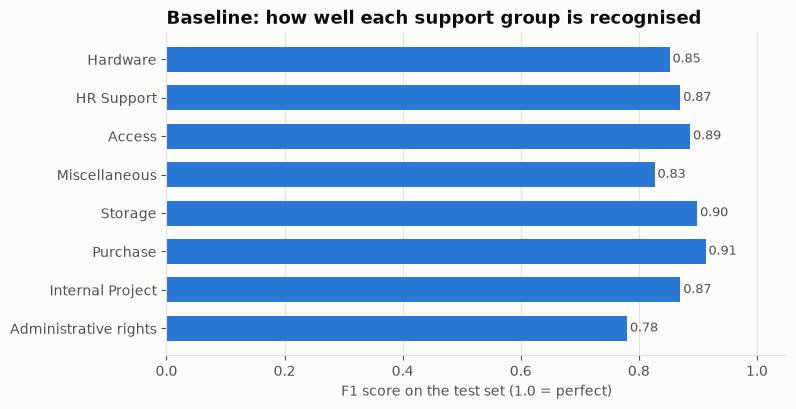

,precision,recall,f1,support
Hardware,0.849,0.855,0.852,2021.0
HR Support,0.882,0.859,0.870,1594.0
Access,0.901,0.873,0.887,1059.0
Miscellaneous,0.805,0.849,0.827,1049.0
Storage,0.900,0.898,0.899,410.0
Purchase,0.924,0.902,0.913,337.0
Internal Project,0.868,0.873,0.870,315.0
Administrative rights,0.763,0.798,0.780,262.0


In [5]:
rep = per_class_report(test.label, test_pred)
rep.to_csv(RESULTS_DIR / "per_class_baseline_tfidf_lr.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
r = rep.reindex(LABELS[::-1])
ax.barh(r.index, r.f1, color=SERIES, height=0.65)
for y, v in enumerate(r.f1):
    ax.text(v + 0.005, y, f"{v:.2f}", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 score on the test set (1.0 = perfect)")
ax.grid(axis="y", visible=False)
ax.set_title("Baseline: how well each support group is recognised")
save(fig, "09_baseline_f1_by_class")
plt.show()
rep.round(3)

## 4. Confusion matrix
Rows = actual group, columns = predicted group.

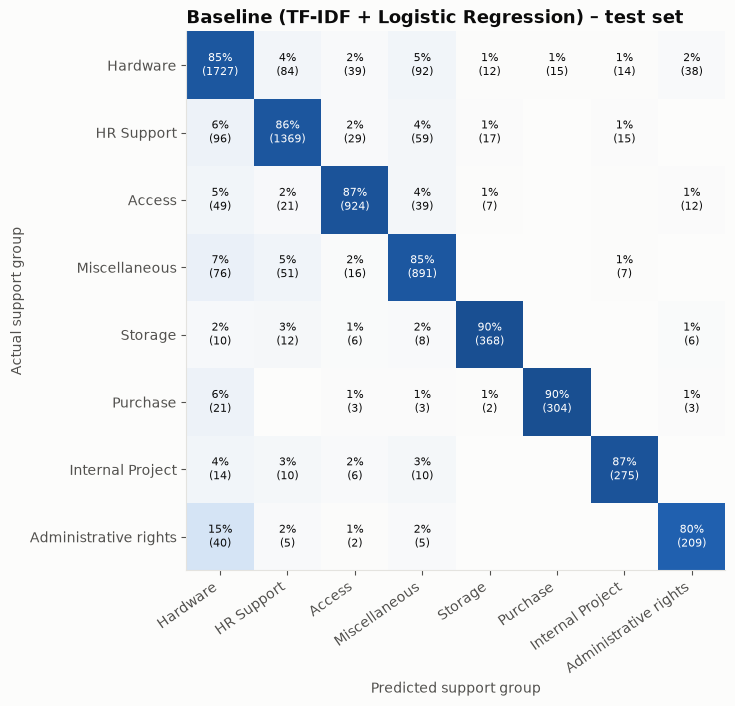

,actual,predicted,tickets
0,HR Support,Hardware,96.0
1,Hardware,Miscellaneous,92.0
2,Hardware,HR Support,84.0
3,Miscellaneous,Hardware,76.0
4,HR Support,Miscellaneous,59.0
5,Miscellaneous,HR Support,51.0


In [6]:
fig, cm = plot_confusion_matrix(test.label, test_pred, "Baseline (TF-IDF + Logistic Regression) – test set",
                                "10_baseline_confusion_matrix")
plt.show()
off = pd.DataFrame(cm, index=LABELS, columns=LABELS)
pairs = (off.where(~np.eye(len(LABELS), dtype=bool)).stack().sort_values(ascending=False).head(6)
           .rename("tickets").rename_axis(["actual", "predicted"]).reset_index())
pairs

## 5. Strongest words per group

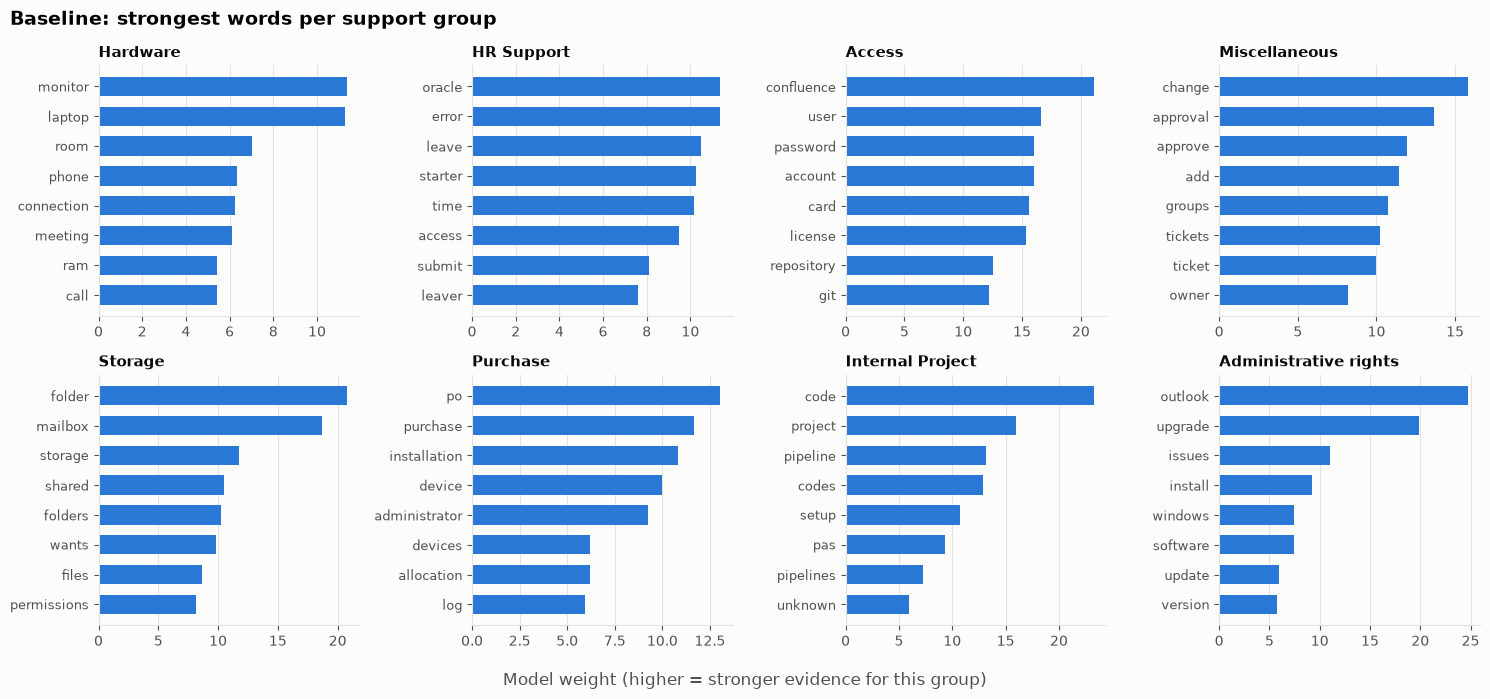

In [7]:
vec = baseline.named_steps["tfidfvectorizer"]
clf = baseline.named_steps["logisticregression"]
vocab = np.array(vec.get_feature_names_out())
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
top_words = {}
for ax, l in zip(axes.flat, LABELS):
    w = clf.coef_[list(clf.classes_).index(l)]
    idx = np.argsort(w)[-8:]
    top_words[l] = list(vocab[idx][::-1])
    ax.barh(vocab[idx], w[idx], color=SERIES, height=0.65)
    ax.set_title(l, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9)
fig.supxlabel("Model weight (higher = stronger evidence for this group)", color=TEXT_SECONDARY)
fig.suptitle("Baseline: strongest words per support group", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "11_baseline_top_words")
plt.show()

## 6. Example errors

In [8]:
preds = pd.read_csv(RESULTS_DIR / "preds_baseline_tfidf_lr.csv")
wrong = preds[preds.label != preds.pred].sort_values("confidence", ascending=False)
print(f"Wrong: {len(wrong)} of {len(preds)} | median confidence when wrong {wrong.confidence.median():.2f}, "
      f"when right {preds[preds.label == preds.pred].confidence.median():.2f}")
pd.set_option("display.max_colwidth", 110)
wrong[["text", "label", "pred", "confidence"]].head(10).round(2)

Wrong: 980 of 7047 | median confidence when wrong 0.51, when right 0.93


,text,label,pred,confidence
767,access to friday pm error dear receiving error please attached asking please thank head,Hardware,HR Support,1.00
4433,oracle time card error card error hello dear have issue with able log card for date range could you please...,Access,HR Support,0.99
4005,wants to access bucharest wednesday july wants hello please location since upload organize files kind rega...,HR Support,Storage,0.99
1576,having issues with the loaner having issues with loaner,Hardware,Administrative rights,0.99
3488,secure data to be added as assignment snow secure added assignment snow hello finds well writing respect l...,Storage,Miscellaneous,0.99
6797,access to ms project thursday pm hi please added licence cost code thanks,Access,Internal Project,0.99
3357,add new team member to git wednesday november pm re add member latest he according please fix give rights ...,Access,Miscellaneous,0.98
1976,enter time oracle pm va leave maternity leave ext friday re pare maternity leave care precedent si card ca...,Hardware,HR Support,0.98
625,add member to mail technical excellence hello please add make her owners thanks friday november technical ...,Hardware,Miscellaneous,0.98
1850,signed signed hello please log assign best regards senior engineer wednesday pm signed hi please example c...,Miscellaneous,Hardware,0.98
